# Fase 2 — Análisis exploratorio de datos funcionales

**Ítem 2 de la rúbrica (15 %).** Para obtener 5 se pide:

1. **media funcional** calculada paso a paso y **verificada contra la función de librería**;
2. **varianza** y **desviación estándar** funcional;
3. **covarianza** y **correlación** funcional de cada fuente;
4. **derivadas** e interpretación del **inicio y fin de las temporadas de lluvia**;
5. **profundidad (Fraiman–Muniz y MBD)** y **boxplot funcional**, con las curvas atípicas **identificadas por estación y año**;
6. **interpretación climatológica** de cada resultado: régimen bimodal, orografía, ENSO.

Tope: analizar solo un subconjunto de años o estaciones **sin justificar** que es representativo → máximo 2. Aquí se usan **todas** las curvas construidas en la fase 1; las únicas exclusiones (píxeles de océano y año 2013 del satélite) se justifican abajo.

Se sigue el script de clase *Análisis exploratorio de datos funcionales* (media con los coeficientes medios, `mean.fd`, `std.fd`, `var.fd`, `cor.fd`, `deriv.fd`, `depth.FM`, `fbplot` con MBD). Los cálculos se programan con `numpy`, y la librería `scikit-fda` (equivalente de `fda`/`fda.usc` en Python) se usa para **verificar**.

In [ ]:
# Verificación reproducible: no reinstala paquetes presentes ni instala sin autorización.
from importlib.util import find_spec
import subprocess
import sys

INSTALAR_FALTANTES = False  # Cambiar a True únicamente si se autoriza instalar en este entorno.
PAQUETES_REQUERIDOS = {'pandas': 'pandas', 'numpy': 'numpy', 'matplotlib': 'matplotlib', 'scipy': 'scipy', 'skfda': 'scikit-fda'}
faltantes = {modulo: paquete for modulo, paquete in PAQUETES_REQUERIDOS.items()
             if find_spec(modulo) is None}

if faltantes and INSTALAR_FALTANTES:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *faltantes.values()])
    faltantes = {modulo: paquete for modulo, paquete in PAQUETES_REQUERIDOS.items()
                 if find_spec(modulo) is None}

if faltantes:
    comando = f"{sys.executable} -m pip install {' '.join(faltantes.values())}"
    raise ModuleNotFoundError(
        f"Faltan dependencias: {faltantes}. No se instalaron automáticamente. "
        f"Autorice la instalación o ejecute: {comando}"
    )

versiones = {modulo: __import__(modulo).__version__
             for modulo in PAQUETES_REQUERIDOS
             if hasattr(__import__(modulo), '__version__')}
print('Dependencias verificadas:', versiones)


In [1]:
from pathlib import Path
import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.integrate import simpson

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 9})
ROOT = Path.cwd(); F1 = ROOT / "fda_fase1"; E0 = ROOT / "eda_fase0"; OUT = ROOT / "fda_fase2"; OUT.mkdir(exist_ok=True)
spec = json.loads((F1 / "base_especificacion.json").read_text())
RANGO, ORDEN, K_EST, K_SAT = tuple(spec["rango"]), spec["orden"], spec["K_estaciones"], spec["K_satelite"]
t = np.arange(1, 366, dtype=float)                      # rejilla diaria común
MESES = [1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335]
def ejes_meses(ax):
    ax.set_xticks(MESES); ax.set_xticklabels(list("EFMAMJJASOND")); ax.set_xlim(1, 365)
print(spec["escala"], "| K estaciones =", K_EST, "| K satélite =", K_SAT)


mm/dia (la raiz se aplica despues, en la fase 4) | K estaciones = 8 | K satélite = 11


## 1. Datos funcionales de la fase 1

- **Estaciones:** 4 485 curvas estación‑año (1981–2003), base B‑spline cúbica con K = 8 (elegido solo con entrenamiento, fase 1).
- **Satélite:** curvas píxel‑año (1981–2003, periodo del proyecto), K = 11. Los **90 píxeles de océano ya se excluyeron en la fase 1** (también de la selección de K): el producto entregado los trae rellenados y no hay pluviómetros en el mar (la máscara viene de CHIRPS v2, notebook 02). Aquí la máscara se vuelve a aplicar solo como control. Las péntadas de 2004–2013 quedan fuera del periodo del proyecto. Quedan 1 353 píxeles × 23 años = 31 119 curvas.

La base se reconstruye con la misma función de Cox–de Boor de la fase 1. Una curva funcional es x(t) = cᵀφ(t).

In [2]:
def nodos(rango, K, orden=ORDEN):
    a, b = rango; return np.r_[[a] * orden, np.linspace(a, b, K - orden + 2)[1:-1], [b] * orden]

def base_en_nodos(t, tau, m):
    # B‑splines de orden m sobre el vector de nodos tau (Cox–de Boor)
    t = np.asarray(t, float)
    B = np.zeros((len(t), len(tau) - 1))
    for j in range(len(tau) - 1):
        B[:, j] = (t >= tau[j]) & (t < tau[j + 1])
    B[t == tau[-1], np.max(np.flatnonzero(tau[:-1] < tau[1:]))] = 1
    for k in range(2, m + 1):
        Bn = np.zeros((len(t), len(tau) - k))
        for j in range(len(tau) - k):
            d1, d2 = tau[j + k - 1] - tau[j], tau[j + k] - tau[j + 1]
            Bn[:, j] = ((t - tau[j]) / d1 * B[:, j] if d1 > 0 else 0) + ((tau[j + k] - t) / d2 * B[:, j + 1] if d2 > 0 else 0)
        B = Bn
    return B

def base_bspline(t, K, orden=ORDEN):
    return base_en_nodos(t, nodos(RANGO, K, orden), orden)

ce = np.load(F1 / "coeficientes_estaciones.npz"); cs = np.load(F1 / "coeficientes_satelite.npz")
C_est, est_id, est_anio = ce["coef"], ce["station_id"], ce["anio"]
est_cuenca = np.where(pd.Series(est_id).astype(str).str[:2] == "26", "Cauca", "Pacífico")

mask = np.ones(39 * 37, bool)
f_ch = ROOT / "datos_web" / "chirps_v2_valle_1981_2013.bin"
if f_ch.exists():
    mask = np.fromfile(f_ch, dtype="<f4", count=39 * 37) > -100          # tierra según CHIRPS v2
tierra = mask[cs["fila"] * 37 + cs["col"]]
C_sat = cs["coef"][tierra].astype(float)
sat_anio, sat_fila, sat_col = cs["anio"][tierra], cs["fila"][tierra], cs["col"][tierra]
sat_lon = -77.55 + .05 * (sat_col + .5); sat_lat = 5.0 - .05 * (sat_fila + .5)
sat_region = np.where(sat_lon < -76.8, "Pacífico", "Cauca")

Phi_e, Phi_s = base_bspline(t, K_EST), base_bspline(t, K_SAT)
Ye = C_est @ Phi_e.T            # estaciones evaluadas en los 365 días
Xs = C_sat @ Phi_s.T            # satélite evaluado en los 365 días
print(f"Estaciones: {Ye.shape} | Satélite (tierra, 1981–2003): {Xs.shape} | píxeles de océano excluidos: {(~mask).sum()}")


Estaciones: (4485, 365) | Satélite (tierra, 1981–2003): (31119, 365) | píxeles de océano excluidos: 90


## 2. Media funcional paso a paso y verificación contra la librería

Como la curva es lineal en sus coeficientes, la media de las curvas es la curva de los coeficientes medios:

$$\bar x(t)=\frac1N\sum_{i=1}^N c_i^\top\phi(t)=\bar c^\top\phi(t)$$

Se calcula así (paso a paso), se compara con la media punto a punto de las curvas evaluadas y con `FDataBasis.mean()` de scikit‑fda, el equivalente de `mean.fd()` de clase.

In [3]:
import skfda
from skfda.representation.basis import BSplineBasis
media_e = Phi_e @ C_est.mean(0)            # paso a paso: c̄ᵀφ(t)
media_s = Phi_s @ C_sat.mean(0)

def fd_libreria(C, K):
    base = BSplineBasis(domain_range=RANGO, n_basis=K, order=ORDEN)
    return skfda.FDataBasis(base, C)
fd_e, fd_s = fd_libreria(C_est, K_EST), fd_libreria(C_sat, K_SAT)
lib_e = fd_e.mean()(t).ravel(); lib_s = fd_s.mean()(t).ravel()
print("Estaciones: max|paso a paso − scikit‑fda| =", f"{np.abs(media_e - lib_e).max():.1e}",
      "| − media de curvas evaluadas =", f"{np.abs(media_e - Ye.mean(0)).max():.1e}")
print("Satélite:   max|paso a paso − scikit‑fda| =", f"{np.abs(media_s - lib_s).max():.1e}",
      "| − media de curvas evaluadas =", f"{np.abs(media_s - Xs.mean(0)).max():.1e}")
# la base de scikit‑fda es la misma que la nuestra
print("Base propia vs base de scikit‑fda:", f"{np.abs(Phi_e - BSplineBasis(domain_range=RANGO, n_basis=K_EST, order=ORDEN)(t)[:, :, 0].T).max():.1e}")


Estaciones: max|paso a paso − scikit‑fda| = 3.6e-15 | − media de curvas evaluadas = 4.3e-14
Satélite:   max|paso a paso − scikit‑fda| = 5.3e-15 | − media de curvas evaluadas = 2.1e-13
Base propia vs base de scikit‑fda: 2.2e-16


## 3. Varianza, desviación estándar y coeficiente de variación funcional

$$\widehat{\mathrm{Var}}(t)=\frac{1}{N-1}\sum_i\big(x_i(t)-\bar x(t)\big)^2,\qquad \mathrm{DE}(t)=\sqrt{\widehat{\mathrm{Var}}(t)},\qquad \mathrm{CV}(t)=\frac{\mathrm{DE}(t)}{\bar x(t)}$$

Varianza estaciones: max|paso − scikit‑fda| = 5.7e-14


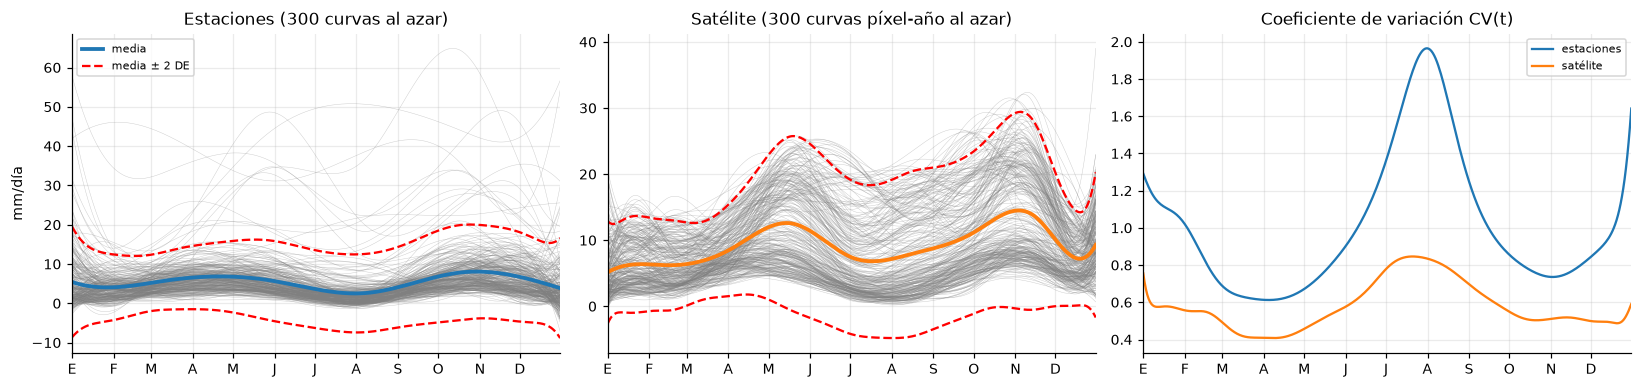

Estaciones: DE máxima 7.02 mm/día el día 1, mínima 3.58 el día 60; CV entre 0.61 y 1.97
   CV en días clave — 15 ene: 1.12 | 1 may: 0.67 | 1 ago: 1.97 | 1 nov: 0.74 | 20 dic: 1.04
Satélite: DE máxima 7.46 mm/día el día 310, mínima 2.95 el día 72; CV entre 0.41 y 0.85
   CV en días clave — 15 ene: 0.58 | 1 may: 0.46 | 1 ago: 0.83 | 1 nov: 0.51 | 20 dic: 0.49


In [4]:
def var_paso(Y, m):  return ((Y - m) ** 2).sum(0) / (len(Y) - 1)
var_e, var_s = var_paso(Ye, media_e), var_paso(Xs, media_s)
de_e, de_s = np.sqrt(var_e), np.sqrt(var_s)
lib_var_e = fd_e.to_grid(t).var(correction=1).data_matrix.ravel()      # correction=1 -> divide por N−1
print("Varianza estaciones: max|paso − scikit‑fda| =", f"{np.abs(var_e - lib_var_e).max():.1e}")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
idx = np.random.default_rng(0).choice(len(Ye), 300, replace=False)
ax[0].plot(t, Ye[idx].T, c="grey", lw=.3, alpha=.4)
ax[0].plot(t, media_e, c="C0", lw=2.5, label="media"); ax[0].plot(t, media_e + 2 * de_e, "r--", lw=1.5, label="media ± 2 DE")
ax[0].plot(t, media_e - 2 * de_e, "r--", lw=1.5); ax[0].set(title="Estaciones (300 curvas al azar)", ylabel="mm/día"); ax[0].legend(fontsize=7)
idx = np.random.default_rng(0).choice(len(Xs), 300, replace=False)
ax[1].plot(t, Xs[idx].T, c="grey", lw=.3, alpha=.4)
ax[1].plot(t, media_s, c="C1", lw=2.5); ax[1].plot(t, media_s + 2 * de_s, "r--", lw=1.5); ax[1].plot(t, media_s - 2 * de_s, "r--", lw=1.5)
ax[1].set(title="Satélite (300 curvas píxel‑año al azar)")
ax[2].plot(t, de_e / media_e, c="C0", label="estaciones"); ax[2].plot(t, de_s / media_s, c="C1", label="satélite")
ax[2].set(title="Coeficiente de variación CV(t)"); ax[2].legend(fontsize=7)
for a in ax: ejes_meses(a)
plt.tight_layout(); plt.show()
for nom, m, d in [("Estaciones", media_e, de_e), ("Satélite", media_s, de_s)]:
    print(f"{nom}: DE máxima {d.max():.2f} mm/día el día {t[d.argmax()]:.0f}, mínima {d.min():.2f} el día {t[d.argmin()]:.0f}; "
          f"CV entre {np.min(d/m):.2f} y {np.max(d/m):.2f}")
    print(f"   CV en días clave — 15 ene: {(d/m)[14]:.2f} | 1 may: {(d/m)[120]:.2f} | 1 ago: {(d/m)[212]:.2f} | 1 nov: {(d/m)[304]:.2f} | 20 dic: {(d/m)[353]:.2f}")


**Lectura.**
- La **media** muestra el **régimen bimodal** del occidente colombiano: dos temporadas de lluvia, una en marzo‑mayo y otra más fuerte en octubre‑noviembre, separadas por la temporada seca de mitad de año (julio‑agosto, el "veranillo") y la de diciembre‑febrero. La causa es el doble paso de la Zona de Convergencia Intertropical (ZCIT) sobre la región.
- La **DE** es grande frente a la media porque mezcla dos fuentes de variación: **dónde** está la estación o el píxel (de ~1 000 mm/año en el valle a >6 000 en la costa) y **qué año** es (ENSO).
- El **CV** es más alto en las temporadas secas, sobre todo a comienzos de agosto (estaciones 1,97; satélite 0,83), y más bajo en las temporadas de lluvia (≈0,7 en estaciones y ≈0,45–0,5 en el satélite el 1 de mayo y el 1 de noviembre). En la temporada seca unos años y lugares tienen lluvia y otros casi nada; en la lluviosa llueve en todas partes. El CV de las estaciones es el doble que el del satélite: el pluviómetro mide un punto y el píxel promedia ~30 km², lo que suaviza la variabilidad.
- Los máximos de DE y CV de las estaciones el 31 de diciembre son **efecto de borde** de la base con K = 8 (los extremos del dominio quedan poco determinados). No son clima.

## 4. Covarianza y correlación funcional

Paso a paso, con los coeficientes centrados (como en clase):

$$\hat\Sigma_c=\frac{1}{N-1}\sum_i (c_i-\bar c)(c_i-\bar c)^\top,\qquad \widehat{\mathrm{Cov}}(s,t)=\phi(s)^\top\hat\Sigma_c\,\phi(t),\qquad \mathrm{Cor}(s,t)=\frac{\mathrm{Cov}(s,t)}{\sqrt{\mathrm{Var}(s)\mathrm{Var}(t)}}$$

La diagonal de la covarianza es la varianza de la §3.

Covarianza estaciones: max|paso − scikit‑fda| = 5.0e-14 | diagonal − varianza: 1.1e-13


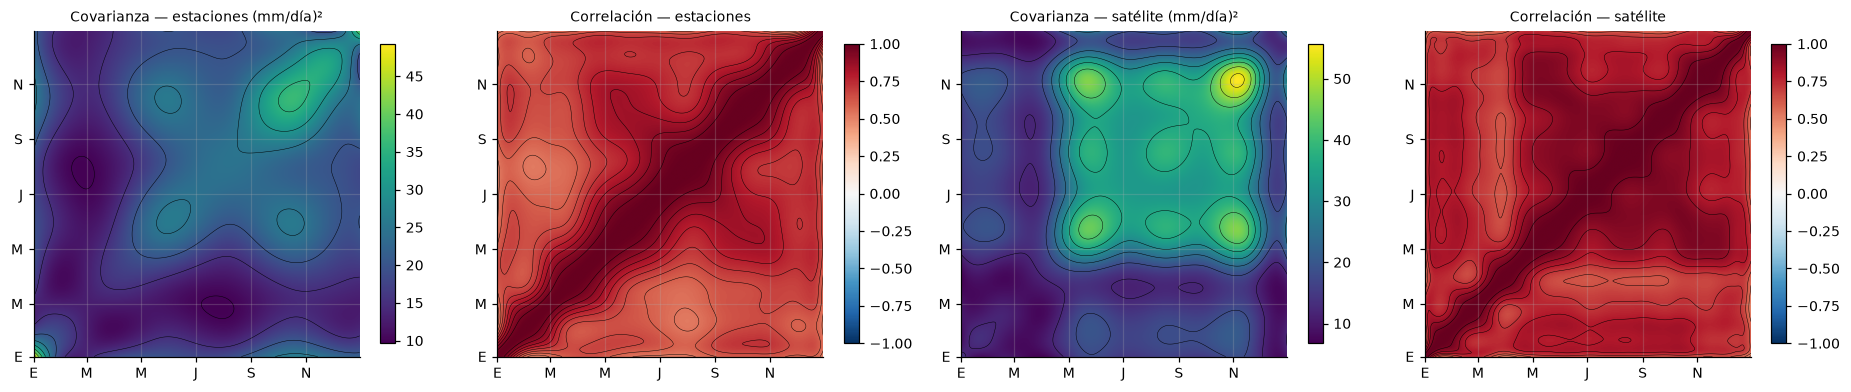

Correlación abril‑octubre (días 105 y 290): estaciones 0.77, satélite 0.82
Correlación enero‑julio  (días 15 y 200): estaciones 0.60, satélite 0.81


In [5]:
def cov_paso(C, Phi):
    Cc = C - C.mean(0); Sc = Cc.T @ Cc / (len(C) - 1); return Phi @ Sc @ Phi.T
cov_e, cov_s = cov_paso(C_est, Phi_e), cov_paso(C_sat, Phi_s)
cor_e = cov_e / np.sqrt(np.outer(np.diag(cov_e), np.diag(cov_e)))
cor_s = cov_s / np.sqrt(np.outer(np.diag(cov_s), np.diag(cov_s)))
lib_cov = fd_e.to_grid(t).cov(t, t, correction=1)
print("Covarianza estaciones: max|paso − scikit‑fda| =", f"{np.abs(cov_e - lib_cov).max():.1e}",
      "| diagonal − varianza:", f"{np.abs(np.diag(cov_e) - var_e).max():.1e}")

fig, ax = plt.subplots(1, 4, figsize=(17, 3.9))
for a, M, tit, cm, lim in [(ax[0], cov_e, "Covarianza — estaciones (mm/día)²", "viridis", None),
                           (ax[1], cor_e, "Correlación — estaciones", "RdBu_r", (-1, 1)),
                           (ax[2], cov_s, "Covarianza — satélite (mm/día)²", "viridis", None),
                           (ax[3], cor_s, "Correlación — satélite", "RdBu_r", (-1, 1))]:
    im = a.imshow(M, origin="lower", extent=[1, 365, 1, 365], cmap=cm, vmin=None if lim is None else lim[0], vmax=None if lim is None else lim[1])
    a.contour(t, t, M, levels=8, colors="k", linewidths=.3); a.set_title(tit, fontsize=9); plt.colorbar(im, ax=a, shrink=.75)
    a.set_xticks(MESES[::2]); a.set_xticklabels(list("EMMJSN")); a.set_yticks(MESES[::2]); a.set_yticklabels(list("EMMJSN"))
plt.tight_layout(); plt.show()
print(f"Correlación abril‑octubre (días 105 y 290): estaciones {cor_e[104, 289]:.2f}, satélite {cor_s[104, 289]:.2f}")
print(f"Correlación enero‑julio  (días 15 y 200): estaciones {cor_e[14, 199]:.2f}, satélite {cor_s[14, 199]:.2f}")


**Lectura.**
- La covarianza es más alta en las **temporadas de lluvia**, sobre todo en octubre‑noviembre: ahí es donde más difieren las curvas entre sí.
- La **correlación** es alta incluso entre fechas lejanas (por ejemplo, la temporada de abril con la de octubre). Una estación o píxel lluvioso lo es todo el año: es el efecto de la **orografía**, que fija el nivel de lluvia de cada sitio. Esto se ve más fuerte en el satélite, que incluye toda la vertiente Pacífica.
- En las estaciones, la correlación entre la mitad seca del año y las temporadas húmedas es menor: lo que pasa en julio‑agosto (veranillo) se parece menos al resto del año.
- El suavizado (K = 8 en estaciones) hace que la correlación sea alta entre días cercanos por construcción. No se debe sobreinterpretar la estructura fina a escala de días.

## 5. Derivadas: inicio y fin de las temporadas de lluvia

La derivada de una curva en base B‑spline es Dx(t) = cᵀDφ(t). La derivada de cada B‑spline se programa con la fórmula de la recursión:

$$\frac{d}{dt}B_{j,m}(t)=(m-1)\left[\frac{B_{j,m-1}(t)}{\tau_{j+m-1}-\tau_j}-\frac{B_{j+1,m-1}(t)}{\tau_{j+m}-\tau_{j+1}}\right]$$

Como las curvas están en mm/día, **Dx(t) es la velocidad de cambio de la lluvia (mm/día por día)**: positiva cuando la lluvia aumenta (entrada de la temporada) y negativa cuando disminuye (salida). Los ceros de la derivada marcan los picos y los mínimos. Esto se conecta con el enfoque de clase: la curva acumulada A(t) = ∫₁ᵗ x(u) du tiene como derivada a x(t), la intensidad de lluvia.

**Definición operativa de las temporadas** (para cada curva):
- **pico 1** = máximo en marzo–julio (días 60–200); **pico 2** = máximo en agosto–diciembre (días 230–365);
- **inicio** de cada temporada = día en que la derivada es máxima antes del pico (cuando la lluvia aumenta más rápido); **fin** = día en que la derivada es mínima después del pico (cuando disminuye más rápido).

In [6]:
def deriv_base(t, K, orden=ORDEN):
    tau = nodos(RANGO, K, orden); B = base_en_nodos(t, tau, orden - 1)       # orden m−1 sobre los mismos nodos
    D = np.zeros((len(t), K))
    for j in range(K):
        d1, d2 = tau[j + orden - 1] - tau[j], tau[j + orden] - tau[j + 1]
        D[:, j] = (orden - 1) * ((B[:, j] / d1 if d1 > 0 else 0) - (B[:, j + 1] / d2 if d2 > 0 else 0))
    return D
from scipy.interpolate import BSpline
for K in [K_EST, K_SAT]:
    tau = nodos(RANGO, K); ref = np.column_stack([BSpline(tau, np.eye(K)[j], ORDEN - 1).derivative()(t) for j in range(K)])
    print(f"K={K}: max|Dφ propia − scipy| = {np.abs(deriv_base(t, K) - ref).max():.1e}")
DPhi_e, DPhi_s = deriv_base(t, K_EST), deriv_base(t, K_SAT)
DYe, DXs = C_est @ DPhi_e.T, C_sat @ DPhi_s.T
print("Derivada de la media − media de las derivadas:", f"{np.abs(DPhi_e @ C_est.mean(0) - DYe.mean(0)).max():.1e}")


K=8: max|Dφ propia − scipy| = 1.4e-17
K=11: max|Dφ propia − scipy| = 2.8e-17
Derivada de la media − media de las derivadas: 1.2e-15


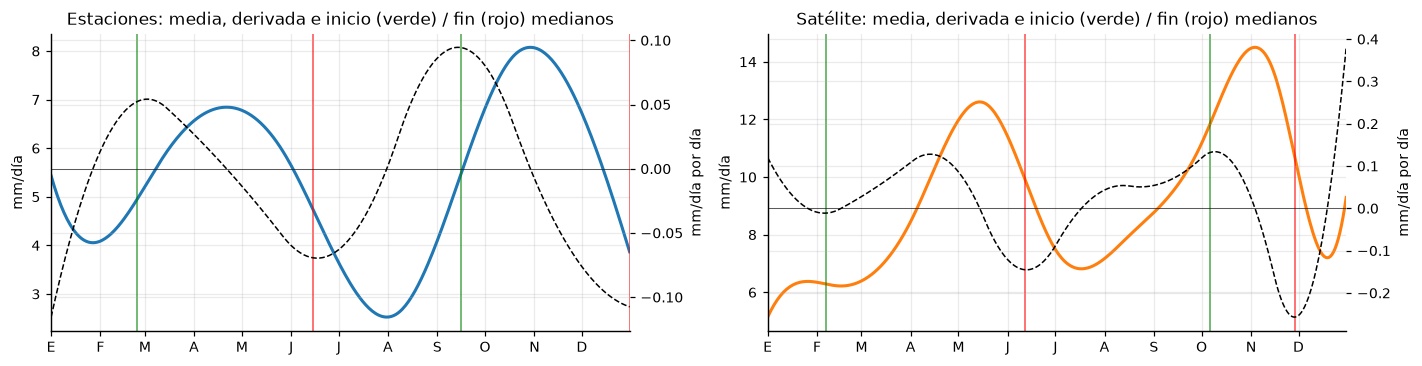

,Estaciones,Satélite
inicio_1,24-Feb (RIC 1–62; sin definir 0%),07-Feb (RIC 1–103; sin definir 0%)
pico_1,15-Apr (RIC 89–129; sin definir 0%),10-May (RIC 118–137; sin definir 0%)
fin_1,15-Jun (RIC 141–175; sin definir 0%),12-Jun (RIC 160–167; sin definir 0%)
inicio_2,16-Sep (RIC 252–294; sin definir 0%),06-Oct (RIC 253–287; sin definir 0%)
pico_2,04-Nov (RIC 292–327; sin definir 0%),04-Nov (RIC 300–313; sin definir 0%)
fin_2,31-Dec (RIC 327–365; sin definir 12%),29-Nov (RIC 331–337; sin definir 13%)


In [7]:
def temporadas(Y, D):
    out = {}
    v1, v2 = (t >= 60) & (t <= 200), (t >= 230) & (t <= 365)
    p1 = np.argmax(np.where(v1, Y, -np.inf), 1); p2 = np.argmax(np.where(v2, Y, -np.inf), 1)
    ii = np.arange(len(Y))[:, None]; T = np.arange(365)[None, :]
    out["inicio_1"] = np.argmax(np.where((T < p1[:, None]) & (T >= 0), D, -np.inf), 1)
    out["pico_1"] = p1
    out["fin_1"] = np.argmin(np.where((T > p1[:, None]) & (T < 230), D, np.inf), 1)
    out["inicio_2"] = np.argmax(np.where((T > 182) & (T < p2[:, None]), D, -np.inf), 1)
    out["pico_2"] = p2
    out["fin_2"] = np.argmin(np.where(T > p2[:, None], D, np.inf), 1)
    df = pd.DataFrame({k: (v + 1).astype(float) for k, v in out.items()})
    df.loc[df.pico_2 >= 365, "fin_2"] = np.nan        # pico en el borde: el fin de la 2.ª temporada no está definido
    return df
tem_e, tem_s = temporadas(Ye, DYe), temporadas(Xs, DXs)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
for a, m, Dm, tem, nom, c in [(ax[0], media_e, DPhi_e @ C_est.mean(0), tem_e, "Estaciones", "C0"), (ax[1], media_s, DPhi_s @ C_sat.mean(0), tem_s, "Satélite", "C1")]:
    a.plot(t, m, c=c, lw=2, label="media x̄(t)"); a2 = a.twinx(); a2.plot(t, Dm, c="k", lw=1, ls="--", label="derivada Dx̄(t)"); a2.axhline(0, c="k", lw=.4)
    for col, mk in [("inicio_1", "▲"), ("fin_1", "▼"), ("inicio_2", "▲"), ("fin_2", "▼")]:
        a.axvline(tem[col].median(), c="g" if "inicio" in col else "r", lw=1, alpha=.7)
    a.set(title=f"{nom}: media, derivada e inicio (verde) / fin (rojo) medianos", ylabel="mm/día"); a2.set_ylabel("mm/día por día"); ejes_meses(a)
plt.tight_layout(); plt.show()

def fecha(d): return (pd.Timestamp("2001-01-01") + pd.Timedelta(days=int(round(d)) - 1)).strftime("%d-%b")
res = pd.DataFrame({f"{nom}": [f"{fecha(tem[c].median())} (RIC {int(tem[c].quantile(.25))}–{int(tem[c].quantile(.75))}; sin definir {tem[c].isna().mean():.0%})" for c in tem.columns]
                    for nom, tem in [("Estaciones", tem_e), ("Satélite", tem_s)]}, index=tem_e.columns)
display(res)


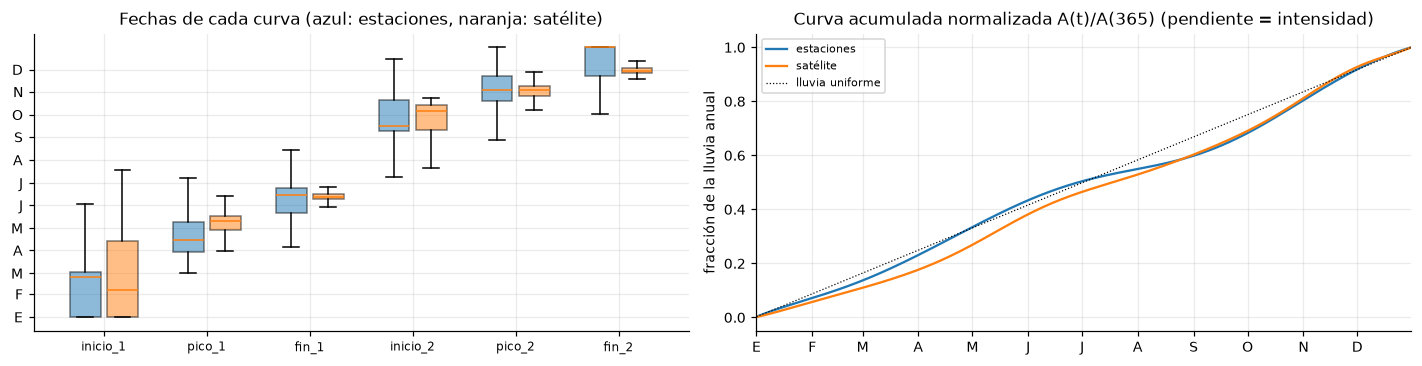

Día en que se alcanza el 50 % de la lluvia anual — estaciones: 29-Jun, satélite: 18-Jul


In [8]:
# Distribución de las fechas por fuente y curva acumulada (enfoque de clase)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
pos = np.arange(6)
bp1 = ax[0].boxplot([tem_e[c].dropna() for c in tem_e.columns], positions=pos - .18, widths=.3, patch_artist=True, showfliers=False)
bp2 = ax[0].boxplot([tem_s[c].dropna() for c in tem_s.columns], positions=pos + .18, widths=.3, patch_artist=True, showfliers=False)
for b, c in [(bp1, "C0"), (bp2, "C1")]:
    for p in b["boxes"]: p.set_facecolor(c); p.set_alpha(.5)
ax[0].set_xticks(pos); ax[0].set_xticklabels(tem_e.columns, fontsize=8); ax[0].set_yticks(MESES); ax[0].set_yticklabels(list("EFMAMJJASOND"))
ax[0].set_title("Fechas de cada curva (azul: estaciones, naranja: satélite)")
A_e = np.cumsum(np.clip(media_e, 0, None)); A_s = np.cumsum(np.clip(media_s, 0, None))
ax[1].plot(t, A_e / A_e[-1], label="estaciones"); ax[1].plot(t, A_s / A_s[-1], label="satélite"); ax[1].plot(t, t / 365, "k:", lw=.8, label="lluvia uniforme")
ax[1].set(title="Curva acumulada normalizada A(t)/A(365) (pendiente = intensidad)", ylabel="fracción de la lluvia anual"); ax[1].legend(fontsize=7); ejes_meses(ax[1])
plt.tight_layout(); plt.show()
print(f"Día en que se alcanza el 50 % de la lluvia anual — estaciones: {fecha(np.argmax(A_e/A_e[-1] >= .5)+1)}, satélite: {fecha(np.argmax(A_s/A_s[-1] >= .5)+1)}")
pd.concat({"estaciones": tem_e.describe().T, "satelite": tem_s.describe().T}).to_csv(OUT / "fechas_temporadas.csv")


**Lectura de las derivadas.**
- **Primera temporada:** la lluvia empieza a aumentar en febrero (aumento más rápido: mediana 24‑feb en estaciones y 07‑feb en satélite). El rango intercuartílico es muy amplio, porque la temporada seca de diciembre‑febrero es poco marcada y en muchas curvas no hay un inicio nítido. El **pico** llega el 15‑abr en las estaciones y el 10‑may en el satélite (≈3,5 semanas más tarde). El **fin**, la caída más rápida, ocurre a mediados de junio en ambas fuentes (15‑jun y 12‑jun).
- **Segunda temporada:** entra a mediados de septiembre en las estaciones y a comienzos de octubre en el satélite (16‑sep y 06‑oct), tiene su pico a comienzos de noviembre en ambas (04‑nov) y en el satélite se retira hacia el 29‑nov. Es la más fuerte de las dos: su pico medio es más alto en ambas fuentes.
- Las fechas de **pico y fin de la primera temporada** y las de la **segunda temporada** son estables (rango intercuartílico de 1–3 semanas). Las de **inicio de la primera temporada** son las más inciertas.
- El "fin de la segunda temporada" de las estaciones (31‑dic) **no es confiable**: es el efecto de borde de la base (K = 8).
- Con la curva acumulada (enfoque de clase), las estaciones alcanzan el 50 % de su lluvia anual el 29‑jun y el satélite el 18‑jul: el satélite carga relativamente más lluvia en la segunda mitad del año.
- Las diferencias de fechas entre fuentes deben confirmarse en la fase 3 con el emparejamiento estación–píxel, porque aquí los conjuntos de curvas no son los mismos sitios.

## 6. Profundidad funcional: Fraiman–Muniz y MBD

Para cada curva xᵢ y cada día t, sea Fₙ,ₜ la función de distribución empírica de los valores x₁(t), …, x_N(t), y r_{it} el rango de xᵢ(t) entre ellos.

- **Fraiman–Muniz (FM):** $\;FM_i=\int\big(1-\big|\tfrac12-F_{n,t}(x_i(t))\big|\big)\,dt$ (como `depth.FM` de clase).
- **Profundidad de bandas modificada (MBD):** proporción media del tiempo que la curva está dentro de la banda formada por cada par de curvas. Con la fórmula de rangos de Sun, Genton y Nychka (2012) no hace falta recorrer los N(N−1)/2 pares:

$$MBD_i=\frac{1}{T}\sum_t\frac{(r_{it}-1)(N-r_{it})+(N-1)}{\binom N2}$$

La integral sobre t se calcula como el promedio sobre la rejilla diaria. Se verifica contra la definición por fuerza bruta y contra scikit‑fda (que integra con la regla de Simpson).

In [9]:
def rangos(Y):
    # rango de cada valor en su columna (1 = menor); empates -> rango máximo (F empírica con ≤)
    orden = np.sort(Y, 0)
    return np.stack([np.searchsorted(orden[:, j], Y[:, j], side="right") for j in range(Y.shape[1])], 1)

def profundidades(Y):
    N = len(Y); r = rangos(Y)
    fm_t = 1 - np.abs(.5 - r / N)
    mbd_t = ((r - 1) * (N - r) + (N - 1)) / (N * (N - 1) / 2)
    return fm_t, mbd_t

# Verificación 1: fórmula de rangos vs definición por pares (fuerza bruta) en 40 curvas
import itertools
Yp = Ye[:40]; _, mbd_t = profundidades(Yp)
bruta = np.array([np.mean([np.mean((np.minimum(Yp[j], Yp[k]) <= Yp[i]) & (Yp[i] <= np.maximum(Yp[j], Yp[k])))
                           for j, k in itertools.combinations(range(40), 2)]) for i in range(40)])
print("MBD rangos vs fuerza bruta:", f"{np.abs(mbd_t.mean(1) - bruta).max():.1e}")

# Verificación 2: contra scikit‑fda (misma regla de integración de Simpson)
from skfda.exploratory import depth as skd
from skfda.exploratory.depth.multivariate import _UnivariateFraimanMuniz
fdg = skfda.FDataGrid(Ye[:500], t); fm_t, mbd_t = profundidades(Ye[:500])
L = t[-1] - t[0]
print("FM  propia vs scikit‑fda:", f"{np.abs(simpson(fm_t, x=t, axis=1) / L - skd.IntegratedDepth(multivariate_depth=_UnivariateFraimanMuniz())(fdg)).max():.1e}")
print("MBD propia vs scikit‑fda:", f"{np.abs(simpson(mbd_t, x=t, axis=1) / L - skd.ModifiedBandDepth()(fdg)).max():.1e}")


MBD rangos vs fuerza bruta: 1.1e-16
FM  propia vs scikit‑fda: 1.1e-15
MBD propia vs scikit‑fda: 5.6e-16


Correlación de Spearman FM vs MBD — estaciones: 0.989, satélite: 0.996
Mediana funcional (FM) de estaciones: estación 2622100102, año 1987 (Cauca)
Mediana funcional (FM) del satélite: píxel (3.325, -76.775), año 1987


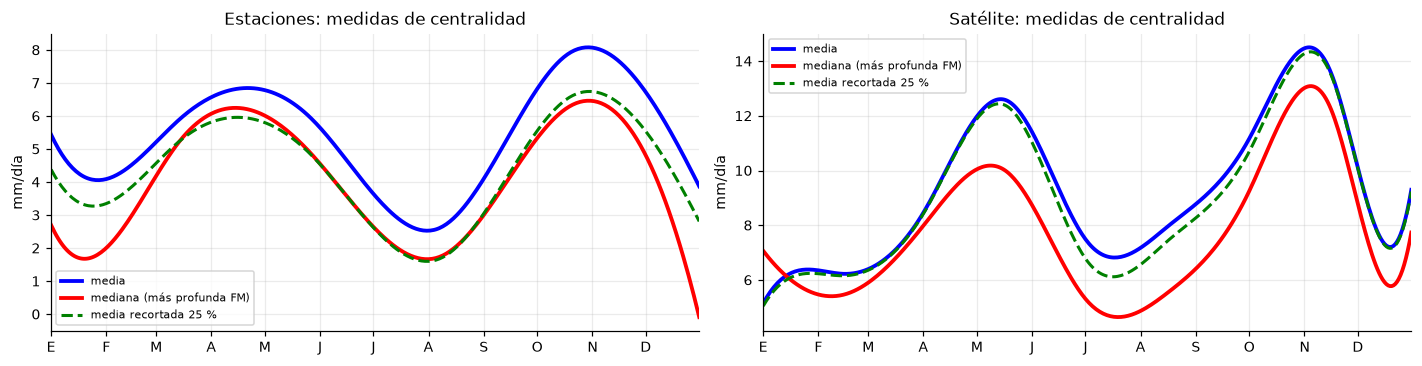

In [10]:
fm_t, mbd_t = profundidades(Ye); FM_e, MBD_e = fm_t.mean(1), mbd_t.mean(1)
fm_t, mbd_t = profundidades(Xs); FM_s, MBD_s = fm_t.mean(1), mbd_t.mean(1)
del fm_t, mbd_t
print(f"Correlación de Spearman FM vs MBD — estaciones: {pd.Series(FM_e).corr(pd.Series(MBD_e), method='spearman'):.3f}, "
      f"satélite: {pd.Series(FM_s).corr(pd.Series(MBD_s), method='spearman'):.3f}")

def centralidad(Y, prof):
    orden = np.argsort(-prof); n25 = int(np.ceil(.75 * len(Y)))
    return Y[orden[0]], Y[orden[:n25]].mean(0)          # mediana funcional y media recortada al 25 %
med_e, rec_e = centralidad(Ye, FM_e); med_s, rec_s = centralidad(Xs, FM_s)
i_med = np.argmax(FM_e)
print(f"Mediana funcional (FM) de estaciones: estación {est_id[i_med]}, año {est_anio[i_med]} ({est_cuenca[i_med]})")
j_med = np.argmax(FM_s); print(f"Mediana funcional (FM) del satélite: píxel ({sat_lat[j_med]:.3f}, {sat_lon[j_med]:.3f}), año {sat_anio[j_med]}")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
for a, Y, m, med, rec, nom in [(ax[0], Ye, media_e, med_e, rec_e, "Estaciones"), (ax[1], Xs, media_s, med_s, rec_s, "Satélite")]:
    a.plot(t, m, c="b", lw=2.5, label="media"); a.plot(t, med, c="r", lw=2.5, label="mediana (más profunda FM)")
    a.plot(t, rec, c="g", lw=2, ls="--", label="media recortada 25 %"); a.set(title=f"{nom}: medidas de centralidad", ylabel="mm/día")
    a.legend(fontsize=7); ejes_meses(a)
plt.tight_layout(); plt.show()


**Lectura de la profundidad.** FM y MBD ordenan las curvas casi igual (Spearman 0,99 y 1,00). La **mediana funcional** queda **por debajo de la media** todos los días en las estaciones (y el 97 % de los días en el satélite), y la media recortada queda entre ambas. La distribución de la lluvia entre sitios es asimétrica: pocos sitios muy lluviosos (costa Pacífica, laderas) jalan la media hacia arriba. Para describir el "año típico" del valle, la mediana es más representativa que la media. La curva más profunda de las estaciones es la 2622100102 en 1987.

## 7. Boxplot funcional (MBD) y curvas atípicas por estación y año

Boxplot funcional de Sun y Genton (2011), el mismo de `fbplot` de clase:
1. se ordenan las curvas por MBD;
2. la **región central** es la envolvente del 50 % de curvas más profundas;
3. los **bigotes** son la región central ampliada 1,5 veces su rango en cada t;
4. una curva es **atípica** si sale de los bigotes en algún día.

Se aplica en tres niveles, porque el atipicismo significa cosas distintas en cada uno:
- **(a) todas las curvas estación‑año:** detecta sitios atípicos (orografía) y años atípicos a la vez;
- **(b) solo estaciones de la cuenca del Cauca:** quita el efecto de la costa Pacífica;
- **(c) curvas anuales medias de cada fuente (una por año):** detecta **años** atípicos.

Atípicas iguales a scikit‑fda (Cauca): True (5 vs 5)


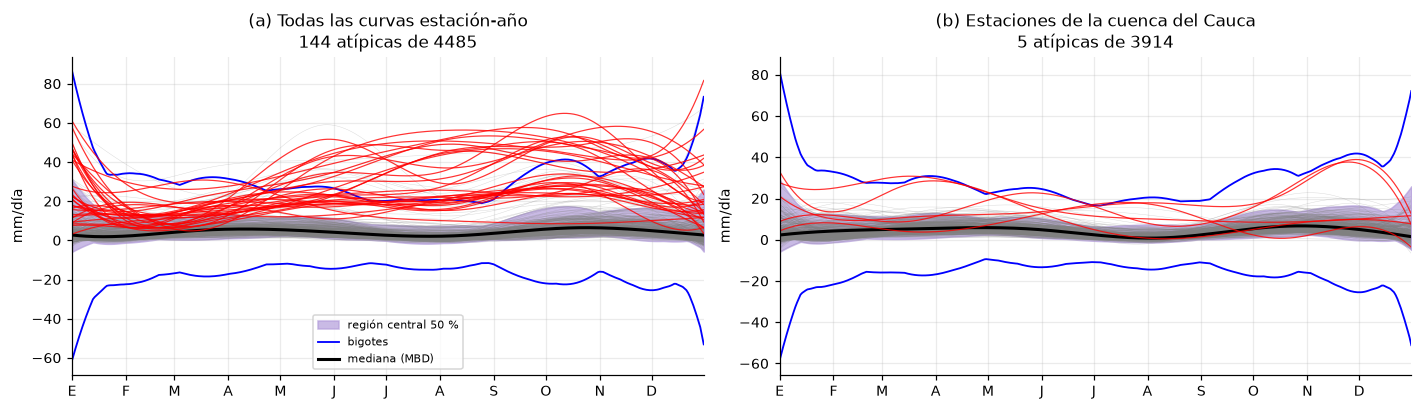

In [11]:
def boxplot_funcional(Y, factor=1.5):
    _, mbd_t = profundidades(Y); prof = mbd_t.mean(1)
    centro = np.argsort(-prof)[: int(np.ceil(len(Y) / 2))]
    lo, hi = Y[centro].min(0), Y[centro].max(0); rango = hi - lo
    inf, sup = lo - factor * rango, hi + factor * rango
    atip = ((Y < inf) | (Y > sup)).any(1)
    return dict(prof=prof, lo=lo, hi=hi, inf=inf, sup=sup, atip=atip, mediana=Y[np.argmax(prof)])

def dibujar(a, Y, bx, titulo, n_gris=400):
    idx = np.random.default_rng(1).choice(len(Y), min(n_gris, len(Y)), replace=False)
    a.plot(t, Y[idx].T, c="grey", lw=.3, alpha=.3)
    a.fill_between(t, bx["lo"], bx["hi"], color="#b39ddb", alpha=.7, label="región central 50 %")
    a.plot(t, bx["sup"], c="b", lw=1.2, label="bigotes"); a.plot(t, bx["inf"], c="b", lw=1.2)
    a.plot(t, bx["mediana"], c="k", lw=2, label="mediana (MBD)")
    if bx["atip"].any(): a.plot(t, Y[bx["atip"]][:30].T, c="r", lw=.8, alpha=.8)
    a.set(title=f"{titulo}\n{bx['atip'].sum()} atípicas de {len(Y)}", ylabel="mm/día"); ejes_meses(a)

bx_e = boxplot_funcional(Ye)
cauca = est_cuenca == "Cauca"; bx_ec = boxplot_funcional(Ye[cauca])

# verificación del boxplot contra scikit‑fda (mismas curvas atípicas) en las estaciones del Cauca
from skfda.exploratory.visualization import Boxplot
bp_lib = Boxplot(skfda.FDataGrid(Ye[cauca], t), depth_method=skd.ModifiedBandDepth(), factor=1.5)
print("Atípicas iguales a scikit‑fda (Cauca):", np.array_equal(np.asarray(bp_lib.outliers), bx_ec["atip"]),
      f"({np.asarray(bp_lib.outliers).sum()} vs {bx_ec['atip'].sum()})")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
dibujar(ax[0], Ye, bx_e, "(a) Todas las curvas estación‑año"); dibujar(ax[1], Ye[cauca], bx_ec, "(b) Estaciones de la cuenca del Cauca")
ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()


In [12]:
# Tabla de curvas atípicas por estación y año
def tabla_atipicas(mask_sub, bx):
    ids, anios, cu = est_id[mask_sub], est_anio[mask_sub], est_cuenca[mask_sub]
    Ysub = Ye[mask_sub]; a = bx["atip"]
    df = pd.DataFrame({"STATION_ID": ids[a], "YEAR": anios[a], "cuenca": cu[a], "MBD": bx["prof"][a].round(4),
                       "media_anual_mm": (Ysub[a].mean(1) * 365).round(0),
                       "dia_max_exceso": [int(t[np.argmax(np.maximum(y - bx["sup"], bx["inf"] - y))]) for y in Ysub[a]],
                       "tipo": np.where((Ysub[a] > bx["sup"]).any(1), "por encima (más lluvia)", "por debajo")})
    return df.sort_values("MBD")
at_a, at_b = tabla_atipicas(np.ones(len(Ye), bool), bx_e), tabla_atipicas(cauca, bx_ec)
print("(a) Atípicas por cuenca:", at_a.cuenca.value_counts().to_dict(), "| estaciones distintas:", at_a.STATION_ID.nunique())
print("(b) Atípicas del Cauca — estaciones con más años atípicos:"); display(at_b.STATION_ID.value_counts().head(8).to_frame("años atípicos").T)
print("(b) Años con más estaciones atípicas:"); display(at_b.YEAR.value_counts().head(8).to_frame("estaciones atípicas").T)
display(at_b.head(12))
at_a.to_csv(OUT / "atipicas_todas_las_estaciones.csv", index=False); at_b.to_csv(OUT / "atipicas_estaciones_cauca.csv", index=False)


(a) Atípicas por cuenca: {'Pacífico': 143, 'Cauca': 1} | estaciones distintas: 15
(b) Atípicas del Cauca — estaciones con más años atípicos:


STATION_ID,2620610103,2620610101,2612810108,2610400101
años atípicos,2,1,1,1


(b) Años con más estaciones atípicas:


YEAR,1988,1990,1982,1997
estaciones atípicas,2,1,1,1


,STATION_ID,YEAR,cuenca,MBD,media_anual_mm,dia_max_exceso,tipo
2,2620610101,1988,Cauca,0.0241,6481.0,186,por encima (más lluvia)
3,2620610103,1988,Cauca,0.0353,6152.0,170,por encima (más lluvia)
4,2620610103,1990,Cauca,0.0694,6038.0,69,por encima (más lluvia)
1,2612810108,1982,Cauca,0.1757,4482.0,119,por encima (más lluvia)
0,2610400101,1997,Cauca,0.2029,2912.0,186,por encima (más lluvia)


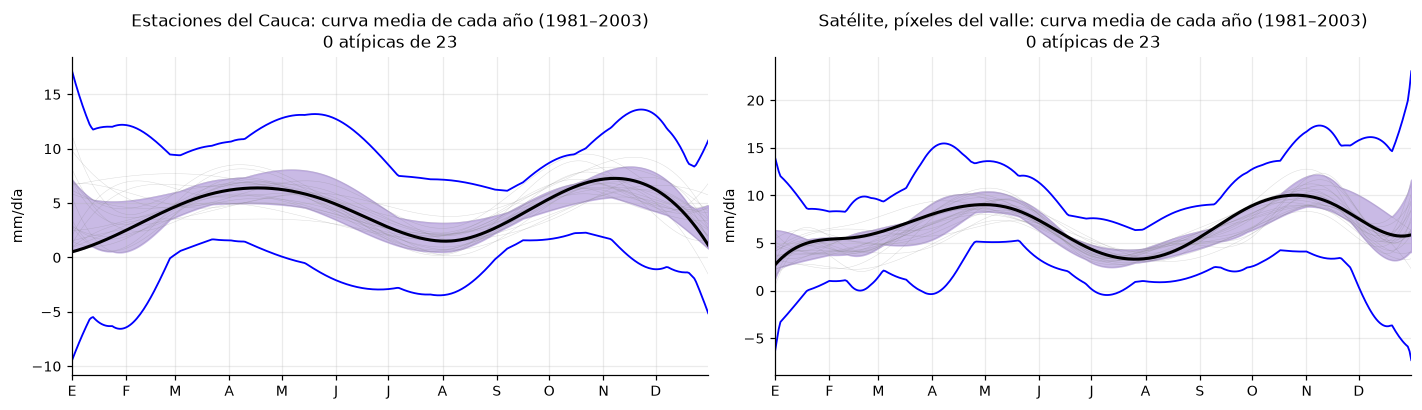

Años menos profundos — estaciones:


anio,1988,1984,1983,1999,1982,1992
MBD,0.267,0.286,0.323,0.332,0.334,0.34
atípico,False,False,False,False,False,False
ONI_anual,-0.89,-0.55,0.46,-1.08,0.91,0.61
fase,Niña,Niña,Neutro,Niña,Niño,Niño


Años menos profundos — satélite:


anio,1985,1983,1999,1984,2000,1995
MBD,0.264,0.299,0.335,0.356,0.356,0.36
atípico,False,False,False,False,False,False
ONI_anual,-0.58,0.46,-1.08,-0.55,-0.77,-0.22
fase,Niña,Neutro,Niña,Niña,Niña,Neutro


In [13]:
# (c) Años atípicos: una curva media por año para cada fuente (región del valle / cuenca del Cauca)
anios_e = np.unique(est_anio[cauca])
Ye_anual = np.stack([Ye[cauca & (est_anio == a)].mean(0) for a in anios_e])
anios_s = np.unique(sat_anio); sc = sat_region == "Cauca"
Xs_anual = np.stack([Xs[sc & (sat_anio == a)].mean(0) for a in anios_s])
bx_ya, bx_xa = boxplot_funcional(Ye_anual), boxplot_funcional(Xs_anual)
oni = pd.read_csv(E0 / "oni_anual_fase.csv", index_col=0) if (E0 / "oni_anual_fase.csv").exists() else None

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for a, Y, bx, anios, nom in [(ax[0], Ye_anual, bx_ya, anios_e, "Estaciones del Cauca: curva media de cada año (1981–2003)"),
                             (ax[1], Xs_anual, bx_xa, anios_s, "Satélite, píxeles del valle: curva media de cada año (1981–2003)")]:
    dibujar(a, Y, bx, nom)
    for y, k in zip(anios, range(len(anios))):
        if bx["atip"][k]: a.annotate(str(y), (t[np.argmax(Y[k])], Y[k].max()), fontsize=7, color="r")
plt.tight_layout(); plt.show()

def prof_anual(anios, bx):
    df = pd.DataFrame({"anio": anios, "MBD": bx["prof"].round(3), "atípico": bx["atip"]}).set_index("anio")
    if oni is not None: df = df.join(oni)
    return df.sort_values("MBD")
pa_e, pa_s = prof_anual(anios_e, bx_ya), prof_anual(anios_s, bx_xa)
print("Años menos profundos — estaciones:"); display(pa_e.head(6).T)
print("Años menos profundos — satélite:"); display(pa_s.head(6).T)
pa_e.to_csv(OUT / "profundidad_anual_estaciones.csv"); pa_s.to_csv(OUT / "profundidad_anual_satelite.csv")


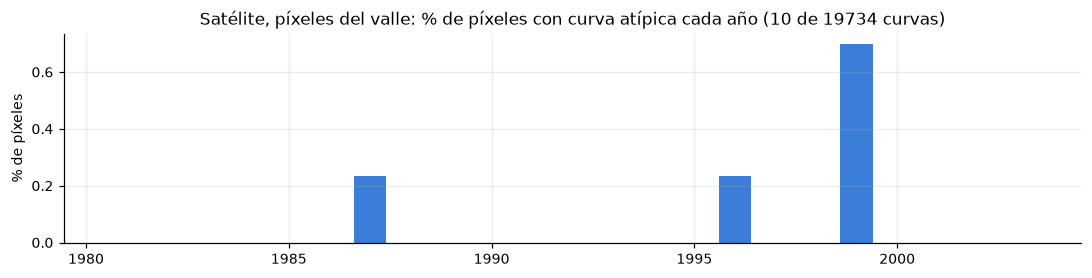

Años con más píxeles atípicos (%): {1999: 0.7, 1996: 0.2, 1987: 0.2, 1983: 0.0, 1984: 0.0}


In [14]:
# Satélite: ¿en qué años se concentran las curvas píxel‑año atípicas? (boxplot de todas las curvas píxel‑año del valle)
bx_sv = boxplot_funcional(Xs[sc])
por_anio = pd.Series(sat_anio[sc][bx_sv["atip"]]).value_counts().reindex(anios_s, fill_value=0)
fig, ax = plt.subplots(figsize=(10, 2.6))
col = ["#d62728" if y in (1985, 1988, 2000) else "#3b7dd8" for y in anios_s]
ax.bar(anios_s, 100 * por_anio.values / (sc & (sat_anio == anios_s[0])).sum(), color=col)
ax.set(title=f"Satélite, píxeles del valle: % de píxeles con curva atípica cada año ({bx_sv['atip'].sum()} de {sc.sum()} curvas)", ylabel="% de píxeles")
plt.tight_layout(); plt.show()
print("Años con más píxeles atípicos (%):", (100 * por_anio / (sc & (sat_anio == anios_s[0])).sum()).sort_values(ascending=False).head(5).round(1).to_dict())


**Lectura del boxplot funcional.** (El boxplot propio y el de scikit‑fda marcan exactamente las mismas curvas atípicas.)
- **(a) Todas las estaciones:** 144 curvas atípicas de 4 485, en 15 estaciones; **143 son de la vertiente Pacífica**. Son atípicas por **dónde** están (orografía), no por el año. Ese boxplot mezcla clima y geografía.
- **(b) Solo la cuenca del Cauca:** 5 atípicas, todas por exceso de lluvia, en 4 estaciones. Dos estaciones (2620610101 y 2620610103) aparecen con 6 000–6 500 mm/año, muy por encima del valle. Es un rasgo del **sitio** (probablemente laderas expuestas; se confirmará con las coordenadas). El año con más estaciones atípicas es **1988** (La Niña).
- **(c) Años:** con la curva media de cada año ninguno sale atípico, pero los menos profundos en las estaciones son 1988, 1984, 1983, 1999 y 1982; tres de ellos (1988, 1984 y 1999) son La Niña: la variación entre años del valle la marca ENSO. En el satélite el año menos profundo es **1985** y **2000** es el quinto: son los déficits del producto ya identificados (notebook 02).
- Con el periodo 1981–2003, casi no hay curvas píxel‑año atípicas en el satélite (el año con más es 1999, La Niña, con 0,7 % de los píxeles del valle). Los años Niña muy lluviosos que el satélite sí registraba (2008, 2010) quedan fuera del periodo del proyecto.

## 8. Interpretación climatológica: orografía y ENSO

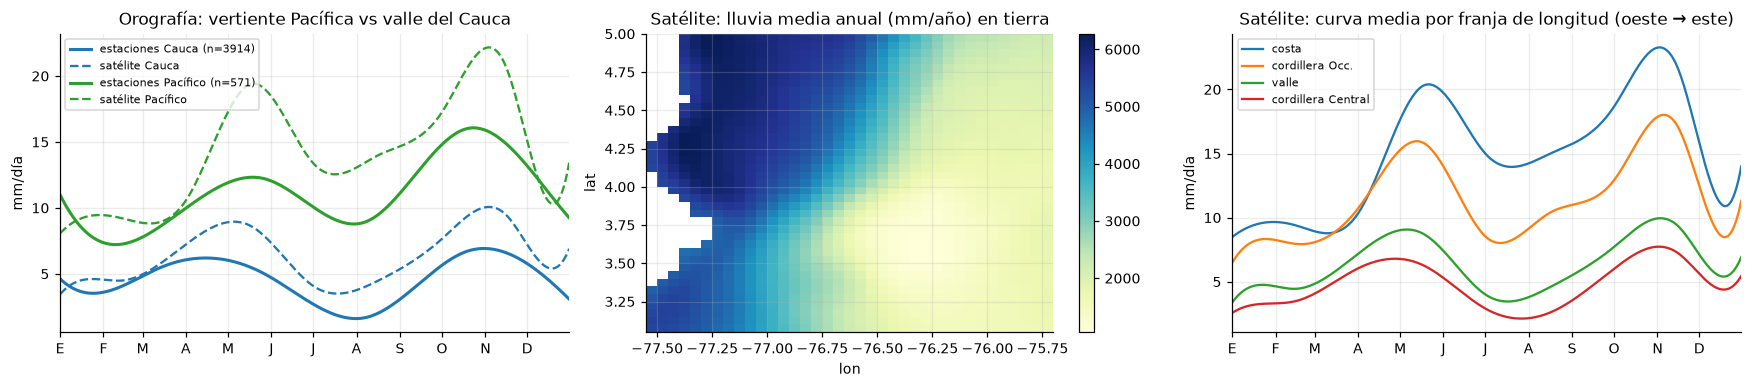

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
for cu, c in [("Cauca", "C0"), ("Pacífico", "C2")]:
    ax[0].plot(t, Ye[est_cuenca == cu].mean(0), c=c, lw=2, label=f"estaciones {cu} (n={np.sum(est_cuenca == cu)})")
    ax[0].plot(t, Xs[sat_region == cu].mean(0), c=c, lw=1.5, ls="--", label=f"satélite {cu}")
ax[0].set(title="Orografía: vertiente Pacífica vs valle del Cauca", ylabel="mm/día"); ax[0].legend(fontsize=7); ejes_meses(ax[0])

clim_px = pd.DataFrame({"lon": sat_lon, "lat": sat_lat, "anual": Xs.mean(1) * 365}).groupby(["lat", "lon"]).anual.mean().unstack()
im = ax[1].imshow(clim_px.values[::-1], extent=[-77.55, -75.70, 3.05, 5.0], cmap="YlGnBu", aspect="auto")
ax[1].set(title="Satélite: lluvia media anual (mm/año) en tierra", xlabel="lon", ylabel="lat"); plt.colorbar(im, ax=ax[1])

bandas = pd.cut(sat_lon, [-77.6, -77.0, -76.6, -76.2, -75.7], labels=["costa", "cordillera Occ.", "valle", "cordillera Central"])
for b in bandas.categories:
    ax[2].plot(t, Xs[np.asarray(bandas == b)].mean(0), label=b)
ax[2].set(title="Satélite: curva media por franja de longitud (oeste → este)", ylabel="mm/día"); ax[2].legend(fontsize=7); ejes_meses(ax[2])
plt.tight_layout(); plt.show()


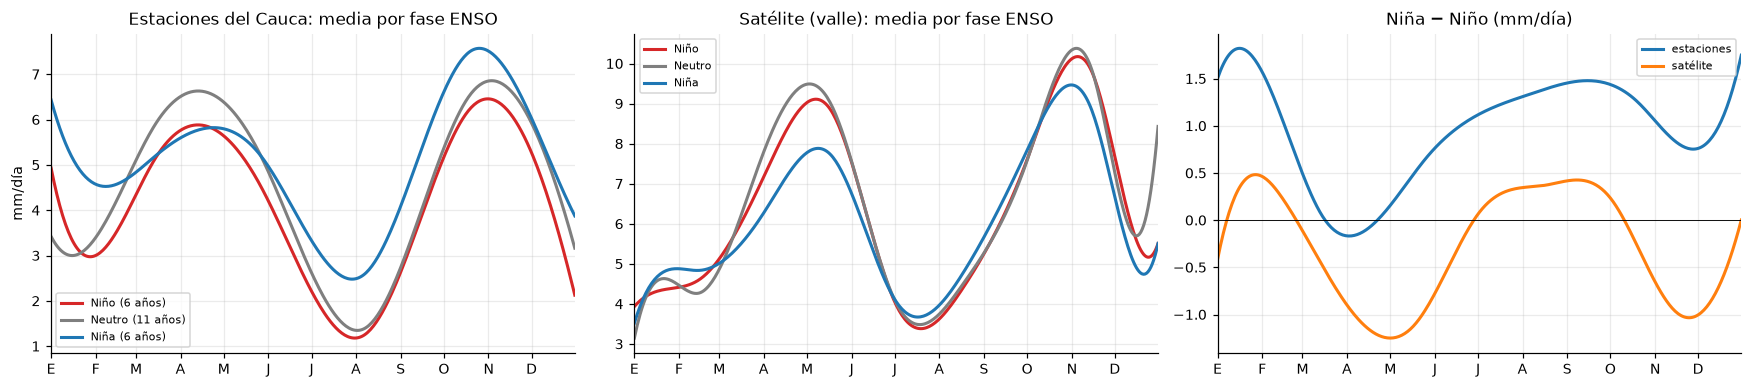

,Niño,Neutro,Niña
estaciones (mm/año),1500.0,1656.0,1851.0
satélite valle (mm/año),2319.0,2368.0,2217.0


Satélite sin 1985, 1988 y 2000 — Niña − Niño (mm/año): 105


In [16]:
if oni is not None:
    fase_e = oni.reindex(est_anio).fase.values; fase_s = oni.reindex(sat_anio).fase.values
    fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
    colores = {"Niño": "#d62728", "Neutro": "#7f7f7f", "Niña": "#1f77b4"}
    for f, c in colores.items():
        ax[0].plot(t, Ye[cauca & (fase_e == f)].mean(0), c=c, lw=2, label=f"{f} ({len(np.unique(est_anio[fase_e == f]))} años)")
        ax[1].plot(t, Xs[sc & (fase_s == f)].mean(0), c=c, lw=2, label=f)
    ax[0].set(title="Estaciones del Cauca: media por fase ENSO", ylabel="mm/día"); ax[1].set(title="Satélite (valle): media por fase ENSO")
    for a in ax[:2]: a.legend(fontsize=7); ejes_meses(a)
    dif_e = Ye[cauca & (fase_e == "Niña")].mean(0) - Ye[cauca & (fase_e == "Niño")].mean(0)
    dif_s = Xs[sc & (fase_s == "Niña")].mean(0) - Xs[sc & (fase_s == "Niño")].mean(0)
    ax[2].plot(t, dif_e, lw=2, label="estaciones"); ax[2].plot(t, dif_s, lw=2, label="satélite"); ax[2].axhline(0, c="k", lw=.6)
    ax[2].set(title="Niña − Niño (mm/día)"); ax[2].legend(fontsize=7); ejes_meses(ax[2])
    plt.tight_layout(); plt.show()
    tot = lambda Y: Y.mean() * 365
    tabla = pd.DataFrame({f: {"estaciones (mm/año)": tot(Ye[cauca & (fase_e == f)]), "satélite valle (mm/año)": tot(Xs[sc & (fase_s == f)])} for f in colores}).round(0)
    display(tabla)
    sat_sin = ~np.isin(sat_anio, [1985, 1988, 2000])
    print("Satélite sin 1985, 1988 y 2000 — Niña − Niño (mm/año):",
          round(tot(Xs[sc & sat_sin & (fase_s == "Niña")]) - tot(Xs[sc & sat_sin & (fase_s == "Niño")])))


**Lectura climatológica.**
- **Orografía.** La vertiente Pacífica recibe varias veces la lluvia del valle y tiene un ciclo menos marcado: llueve casi todo el año. Los vientos húmedos del Pacífico (el chorro del Chocó) chocan con la cordillera Occidental y descargan en la ladera de barlovento. El valle del Cauca queda a sotavento (sombra de lluvia) y conserva el régimen **bimodal** de los Andes colombianos. Las franjas de longitud del satélite muestran esa transición de oeste a este.
- **ENSO en las estaciones.** En el valle del Cauca, los años **La Niña** son más lluviosos (≈1 850 mm/año) y los **El Niño** más secos (≈1 500 mm/año): un 23 % más de lluvia en La Niña, durante todo el año y sobre todo en las temporadas de transición (diciembre‑enero y agosto‑septiembre). Es la respuesta esperada en el occidente colombiano.
- **ENSO en el satélite: casi no responde.** En los píxeles del valle, La Niña da incluso **menos** lluvia que El Niño (≈2 217 frente a 2 319 mm/año), con una diferencia negativa en abril‑junio y noviembre‑diciembre. Sin 1985, 1988 y 2000 la diferencia pasa a apenas +105 mm/año, frente a ≈+350 en las estaciones.
- **Consecuencia para el proyecto:** el **sesgo satelital depende de la fase ENSO**. En años Niña el satélite subestima la lluvia del valle más que en años Niño. Esto justifica incluir el **ONI** en el vector `z` de la red, como pide el enunciado, y reportar las métricas por fase ENSO.

In [17]:
# Guardar resultados de la fase 2
pd.DataFrame({"dia": t, "media_est": media_e, "de_est": de_e, "media_sat": media_s, "de_sat": de_s,
              "mediana_est": med_e, "mediana_sat": med_s}).to_csv(OUT / "media_de_mediana.csv", index=False)
pd.DataFrame({"STATION_ID": est_id, "YEAR": est_anio, "cuenca": est_cuenca, "FM": FM_e, "MBD": MBD_e,
              **{c: tem_e[c].values for c in tem_e.columns}}).to_csv(OUT / "profundidad_y_fechas_estaciones.csv", index=False)
pd.DataFrame({"anio": sat_anio, "fila": sat_fila, "col": sat_col, **{f"c{k+1}": C_sat[:, k] for k in range(K_SAT)}}).to_csv(
    OUT / "coef_satelite_tierra.csv.gz", index=False, float_format="%.6f")          # coeficientes del satélite en tierra (CSV)
pd.DataFrame({"anio": anios_s, "MBD": bx_xa["prof"]}).to_csv(OUT / "mbd_anual_satelite_python.csv", index=False)
print(sorted(p.name for p in OUT.iterdir()))


['atipicas_estaciones_cauca.csv', 'atipicas_todas_las_estaciones.csv', 'coef_satelite_tierra.csv.gz', 'fechas_temporadas.csv', 'figuras_R', 'mbd_anual_satelite_python.csv', 'media_de_mediana.csv', 'profundidad_anual_estaciones.csv', 'profundidad_anual_satelite.csv', 'profundidad_y_fechas_estaciones.csv']


## 9. Resumen para el informe (ítem 2)

| Requisito | Dónde | Resultado |
|---|---|---|
| Media paso a paso verificada con librería | §2 | c̄ᵀφ(t) = `FDataBasis.mean()` de scikit‑fda (diferencia ~1e‑15) |
| Varianza y DE funcional | §3 | DE y CV por fuente; mayor variación relativa en la temporada seca |
| Covarianza y correlación | §4 | φᵀΣ_cφ = scikit‑fda; correlación alta entre temporadas (efecto del sitio/orografía) |
| Derivadas, inicio y fin de temporadas | §5 | Dφ programada (= scipy); fechas de inicio, pico y fin por curva y fuente |
| Profundidad FM y MBD, boxplot | §6–§7 | Fórmulas propias = fuerza bruta = scikit‑fda; atípicas por estación‑año y por año |
| Interpretación climatológica | §3–§8 | Bimodal (ZCIT), orografía (Pacífico vs valle), ENSO (Niña húmedo, Niño seco) |

Salidas en `fda_fase2/`.